This is a demonstrator example for how to get volumes and areas with a stochastic volume calculations. 

In [1]:
import openmc

# Surface definitions
s1 = openmc.Sphere(r=5)
s2 = openmc.model.RectangularParallelepiped(-6,6,-6,6,-6,6)
s3 = openmc.model.RectangularParallelepiped(-10,10,-10,10,-10,10)

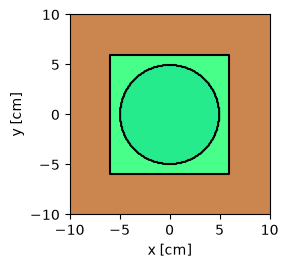

In [2]:
# Cell definitions
c1 = openmc.Cell(cell_id=1, fill=None,region=(-s1))
c2 = openmc.Cell(cell_id=2, region=(+s1 & -s2))
c3 = openmc.Cell(cell_id=3, region=(+s2 & -s3))

# MCNP Guide states that you must list all bounding surfaces explicitly.
# You have to be careful when using complements. So in MCNP, getting the volume of c3 works.

# note: openmc uses stochastic volume calculations, so need bounding box to perform it
# also you do need to call OpenMC to actually do the stochastic volume calculation

# c4 is surface-wise the same as c3; but defined in a way that actually makes the 
# volume calculation fail in MCNP. as seen before, it will fail in OpenMC too
# See that in the next box, Cell 4 gets a volume of 0.
c4 = openmc.Cell(cell_id=4, region=(-s3 & ~(c1.region | c2.region)))
geometry = openmc.Geometry([c1,c2,c3,c4])
geometry.plot(width=(20,20),outline=True)
geometry.export_to_xml()

vol_calc = openmc.VolumeCalculation([c1,c2,c3,c4], 1000000)
# vol_calc.set_trigger(1e-02, 'rel_err')
# trigger can be variance, std_dev, or rel_err. can be quite expensive


In [3]:
settings = openmc.Settings()
settings.run_mode = 'volume'
settings.volume_calculations = [vol_calc]
settings.export_to_xml()
openmc.run(output=True)

vol_calc.load_results("volume_1.h5")

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


In [4]:
print(vol_calc.ids)
c1.add_volume_information(vol_calc)
c2.add_volume_information(vol_calc)
c3.add_volume_information(vol_calc)
c4.add_volume_information(vol_calc)

j=0
for i in [c1,c2,c3,c4]:
    j+=1
    print(rf"cell c{j} volume is {i.volume}")

[1, 2, 3, 4]
cell c1 volume is 521.112
cell c2 volume is 1200.272
cell c3 volume is 6278.616
cell c4 volume is 0.0
